MCS 320 Project Two due Wednesday 28 October 2026 at 1pm

The project illustrates symbolic and numeric integration
to compute the coefficients to approximate functions
in an orthogonal basis of sine and cosine functions.

# 1. An Orthogonal Basis of Periodic Functions

Consider $\sin(k \pi x)$ for $k$ ranging from 1 to 5, over the interval $x \in [-1, +1]$.

In [1]:
sf5 = [sin(k*pi*x) for k in range(1, 6)]
sf5

[sin(pi*x), sin(2*pi*x), sin(3*pi*x), sin(4*pi*x), sin(5*pi*x)]

These 5 functions are orthogonal with respect to the inner product 

$$
   \langle f , g \rangle = \int_{-1}^{+1} f(x) g(x) dx.
$$

In [2]:
integral(sf5[1]*sf5[1], (x, -1, 1))

1

In [3]:
integral(sf5[1]*sf5[2], (x, -1, 1))

0

If we compute all inner products for those five functions, then we obtain the identity matrix.

In [4]:
[[integral(f*g, (x, -1, 1)) for g in sf5] for f in sf5] 

[[1, 0, 0, 0, 0],
 [0, 1, 0, 0, 0],
 [0, 0, 1, 0, 0],
 [0, 0, 0, 1, 0],
 [0, 0, 0, 0, 1]]

We thus have an orthogonal basis.  Let us consider $\cos(k \pi x)$ for $k$ ranging from 0 to 5.

In [5]:
cf5 = [cos(k*pi*x) for k in range(6)]
cf5

[1, cos(pi*x), cos(2*pi*x), cos(3*pi*x), cos(4*pi*x), cos(5*pi*x)]

In [6]:
[[integral(f*g, (x, -1, 1)) for g in cf5] for f in cf5] 

[[2, 0, 0, 0, 0, 0],
 [0, 1, 0, 0, 0, 0],
 [0, 0, 1, 0, 0, 0],
 [0, 0, 0, 1, 0, 0],
 [0, 0, 0, 0, 1, 0],
 [0, 0, 0, 0, 0, 1]]

Also the cosine functions define an orthogonal basis.  Let us see if the sine and cosine functions are orthogonal with respect to each other.

In [7]:
F5 = cf5 + sf5
F5

[1,
 cos(pi*x),
 cos(2*pi*x),
 cos(3*pi*x),
 cos(4*pi*x),
 cos(5*pi*x),
 sin(pi*x),
 sin(2*pi*x),
 sin(3*pi*x),
 sin(4*pi*x),
 sin(5*pi*x)]

In [8]:
[[integral(f*g, (x, -1, 1)) for g in F5] for f in F5] 

[[2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
 [0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0],
 [0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0],
 [0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0],
 [0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0],
 [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0],
 [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1]]

The above computation shows that the cosine and sine functions are orthogonal with respect to the inner product.

# 2. Approximations of Functions

For any function defined $f(x)$ defined over $x \in [-1, +1]$, 
we approximate $f$ as a linear combination of cosine and sine functions running at increasing frequencies.  For some positive integer $n$:

$$
   f(x) \approx \frac{1}{2} a_0 + \sum_{k=1}^n a_k \cos(k \pi x)
                          + \sum_{k=1}^n b_k \sin(k \pi x),
$$

where the coefficients are computed as

$$
   a_k = \int_{-1}^{+1} f(x) \cos(k \pi) dx, \quad k = 0, 1, \ldots, n, 
$$

and

$$
   b_k = \int_{-1}^{+1} f(x) \sin(k \pi) dx, \quad k= 1, 2, \ldots, n.
$$

The formulas for the coefficients follow from the linearity of the integral and the orthogonality of the basis.

In [9]:
f = 2*cos(3*pi*x) + 4*sin(5*pi*x)

In [10]:
c5 = [integral(f*g, (x, -1, 1)) for g in F5]
c5

[0,
 0,
 0,
 1/4*(4*pi + 5)/pi + 1/4*(4*pi - 5)/pi,
 0,
 0,
 0,
 0,
 0,
 0,
 1/8*(16*pi + 5)/pi + 1/8*(16*pi - 5)/pi]

To simplify the coefficients, we compute floating-point approximations, which will turn out to be exact.

In [11]:
C5 = [float(cff) for cff in c5]
C5

[0.0, 0.0, 0.0, 2.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 4.0]

In [12]:
A5 = C5[0]/2 + sum([cff*bf for (cff,bf) in zip(C5[1:],F5[1:])])
A5

2.0*cos(3*pi*x) + 4.0*sin(5*pi*x)

Observe that we recovered the coefficient of the original function $f$.

## assignment one

Consider $f = (\sin(2 \pi x))^3$.

1. Compute approximations for $f$ for increasing values of $n$.
2. Verify the accuracy of the approximations $A$ via plots of $f$ and $A$ over $[-1, 1]$.
3. What should the value of $n$ be for the approximation $A$ to match $f$?

For this problem, exact values for the coefficients in the approximation $A$ are most appropriate.

### answer to assignment one

In [13]:
f = (sin(2*pi*x))^3

In [14]:
c5 = [integral(f*g, (x, -1, 1)) for g in F5]
c5

[0, 0, 0, 0, 0, 0, 0, 3/4, 0, 0, 0]

In [15]:
A5 = c5[0]/2 + sum([cff*bf for (cff, bf) in zip(c5[1:], F5[1:])])
A5

3/4*sin(2*pi*x)

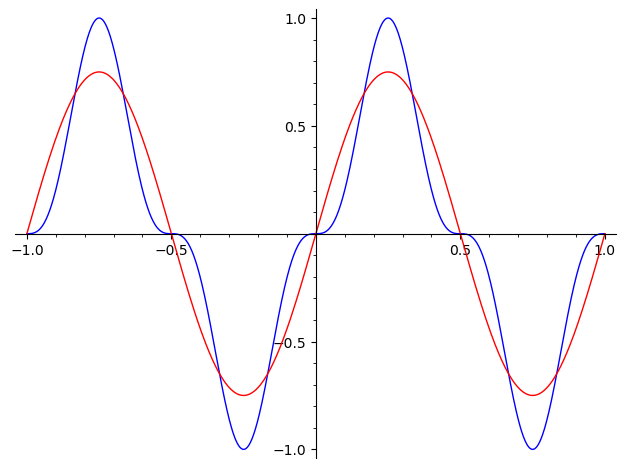

In [16]:
pf = plot(f, (x, -1, 1))
pA5 = plot(A5, (x, -1, 1), color='red')
show(pf+pA5)

In [17]:
n = 6
F6 = [cos(k*pi*x) for k in range(n+1)] + [sin(k*pi*x) for k in range(1, n+1)]
F6

[1,
 cos(pi*x),
 cos(2*pi*x),
 cos(3*pi*x),
 cos(4*pi*x),
 cos(5*pi*x),
 cos(6*pi*x),
 sin(pi*x),
 sin(2*pi*x),
 sin(3*pi*x),
 sin(4*pi*x),
 sin(5*pi*x),
 sin(6*pi*x)]

In [18]:
c6 = [integral(f*g, (x, -1, 1)) for g in F6]
c6

[0, 0, 0, 0, 0, 0, 0, 0, 3/4, 0, 0, 0, -1/4]

In [19]:
A6 = c6[0]/2 + sum([cff*bf for (cff, bf) in zip(c6, F6)])
A6

-1/4*sin(6*pi*x) + 3/4*sin(2*pi*x)

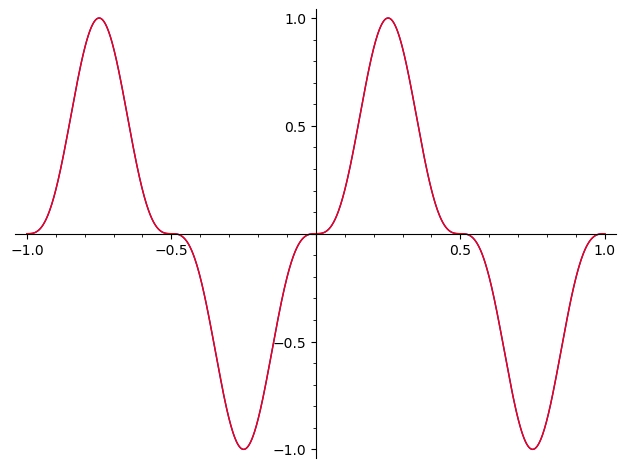

In [20]:
pf = plot(f, (x, -1, 1))
pA6 = plot(A6, (x, -1, 1), color='red')
show(pf+pA6)

We see that for $n = 6$, the plots of the approximation and the function are identical.

# 3. Approximating the Exponential Function

Naturally, the basis of sine and cosine functions works very well to approximate periodic functions.  But what if the function is not periodic?  The next assignment considers the exponential function.

## assignment two

Consider $f = \exp(x)$.

1. Compute approximations $A$ of $f$ for $n=5, 10, 20$.

   For each approximation $A$, plot $f$ and $A$.

   Plot also the error $\mbox{abs}(f - A)$ for $x \in [-1, +1]$.

2. Describe the shape of the approximation and the error,
   comparing the accuracy of the approximations for increasing values of $n$.

### answer to assignment two

In [21]:
f = exp(x)

In [22]:
c5 = [integral(f*g, (x, -1, 1)) for g in F5]
c5

[e - e^(-1),
 -e/(pi^2 + 1) + 1/(pi^2*e + e),
 e/(4*pi^2 + 1) - 1/(4*pi^2*e + e),
 -e/(9*pi^2 + 1) + 1/(9*pi^2*e + e),
 e/(16*pi^2 + 1) - 1/(16*pi^2*e + e),
 -e/(25*pi^2 + 1) + 1/(25*pi^2*e + e),
 pi*e/(pi^2 + 1) - pi/(pi^2*e + e),
 -2*pi*e/(4*pi^2 + 1) + 2*pi/(4*pi^2*e + e),
 3*pi*e/(9*pi^2 + 1) - 3*pi/(9*pi^2*e + e),
 -4*pi*e/(16*pi^2 + 1) + 4*pi/(16*pi^2*e + e),
 5*pi*e/(25*pi^2 + 1) - 5*pi/(25*pi^2*e + e)]

In [23]:
C5 = [float(cff) for cff in c5]
C5

[2.3504023872876028,
 -0.21623624012038967,
 0.05806556991087977,
 -0.02616604195265316,
 0.014790435467972235,
 -0.0094873712094066,
 0.6793261834020946,
 -0.3648367357170488,
 0.24660913551593253,
 -0.18586209363830192,
 0.14902727846675543]

In [24]:
A5 = C5[0]/2 + sum([cff*bf for (cff, bf) in zip(C5[1:], F5[1:])])
A5

-0.0094873712094066*cos(5*pi*x) + 0.014790435467972235*cos(4*pi*x) - 0.02616604195265316*cos(3*pi*x) + 0.05806556991087977*cos(2*pi*x) - 0.21623624012038967*cos(pi*x) + 0.14902727846675543*sin(5*pi*x) - 0.18586209363830192*sin(4*pi*x) + 0.24660913551593253*sin(3*pi*x) - 0.3648367357170488*sin(2*pi*x) + 0.6793261834020946*sin(pi*x) + 1.1752011936438014

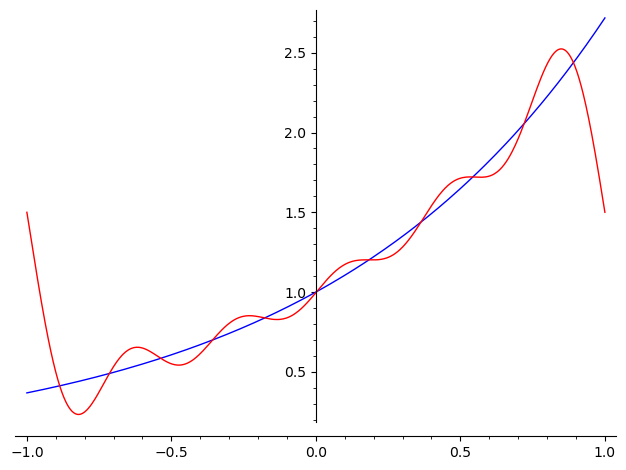

In [25]:
pf = plot(f, (x, -1, 1))
pA5 = plot(A5, (x, -1, 1), color='red')
show(pf+pA5)

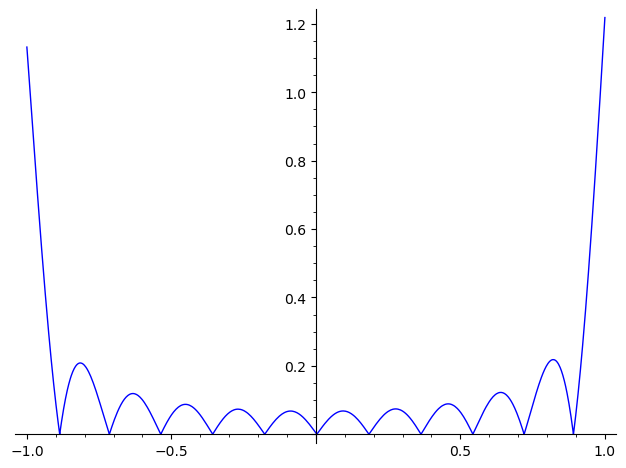

In [26]:
plot(abs(f-A5), (x, -1, 1))

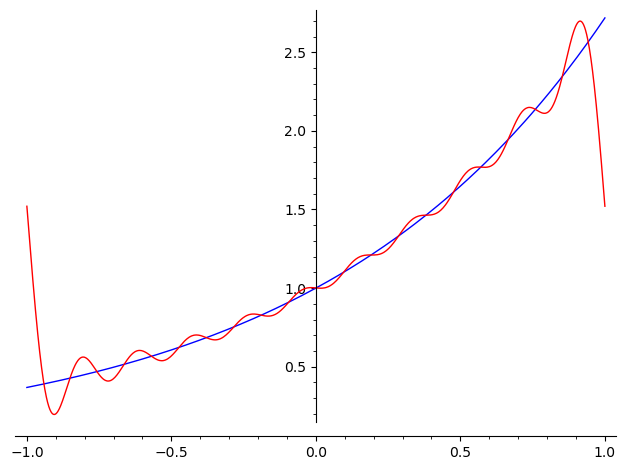

In [27]:
n = 10
F10 = [cos(k*pi*x) for k in range(n+1)] + [sin(k*pi*x) for k in range(1, n+1)]
C10 = [float(integral(f*g, (x, -1, 1))) for g in F10]
A10 = C10[0]/2 + sum([cff*bf for (cff, bf) in zip(C10[1:], F10[1:])])
pA10 = plot(A10, (x, -1, 1), color='red')
show(pf+pA10)

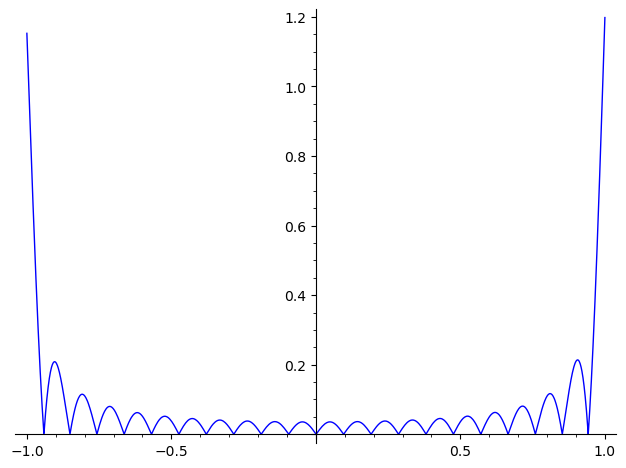

In [28]:
plot(abs(f-A10), (x, -1, 1))

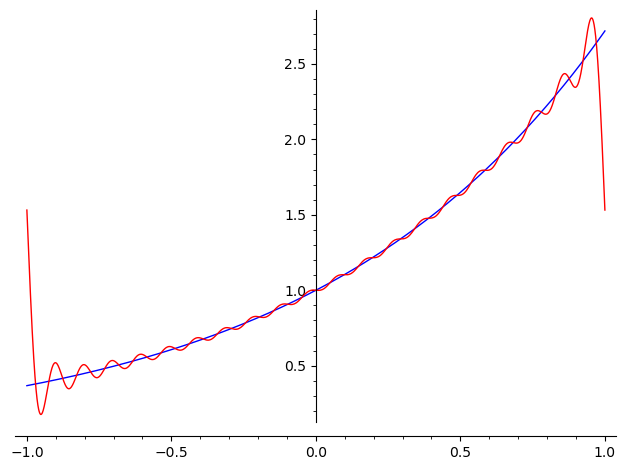

In [29]:
n = 20
F20 = [cos(k*pi*x) for k in range(n+1)] + [sin(k*pi*x) for k in range(1, n+1)]
C20 = [float(integral(f*g, (x, -1, 1))) for g in F20]
A20 = C10[0]/2 + sum([cff*bf for (cff, bf) in zip(C20[1:], F20[1:])])
pA20 = plot(A20, (x, -1, 1), color='red')
show(pf+pA20)

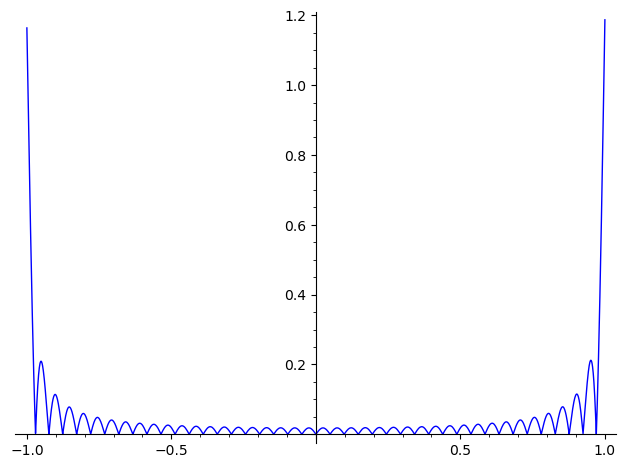

In [30]:
plot(abs(f-A20), (x, -1, 1))

We see that the approximations improve:
1. the shape of $A$ resembles more and more the function $f$, and
2. the error is getting smaller in magnitude.

However, the errors spike at the end points of the interval.

# 4. Approximation of a Piecewise Function

Often, a symbolic antiderivative may not exist, or even as it exists, it may not be useful, as is the case of a piecewise function.

We consider the following:

$$
   f(x) = \left\{
   \begin{array}{ccl}
      -x - 1 & & \mbox{if } x \in [-1, -1/2], \\
       x     & & \mbox{if } x \in (-1/2, +1/2), \\
      -x + 1 & & \mbox{if } x \in [+1/2, +1].
   \end{array}
   \right.
$$

In [31]:
f = piecewise([([-1,-1/2], -x-1), ((-1/2,1/2), x), ([1/2,1], 1-x)]) 

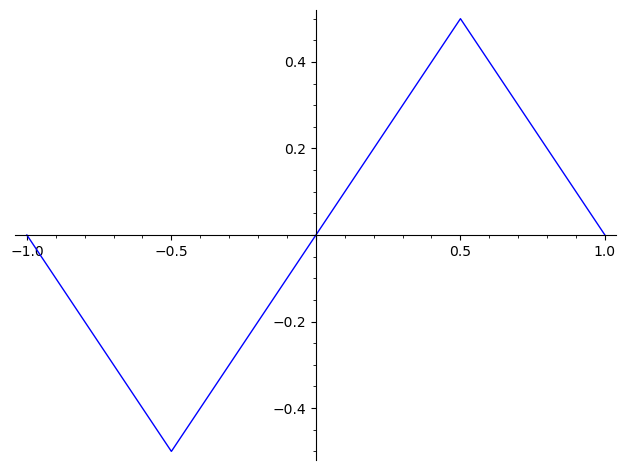

In [32]:
plot(f, (x,-1, 1))

In [33]:
af = integrate(f, x)
af

piecewise(x|-->-1/2*x^2 - x - 1/2 on [-1, -1/2], x|-->1/2*x^2 - 1/4 on (-1/2, 1/2), x|-->-1/2*x^2 + x - 1/2 on [1/2, 1]; x)

In [34]:
af(+1) - af(-1)

0

Although we can compute a symbolic antiderivative of a piecewise function, as this antiderivative is discontinuous, the symbolic definite integration fails.  Therefore, we apply numerical integration as available in the ``quad`` function of the ``integrate`` module of ``scipy``.

In [35]:
from scipy.integrate import quad

The input to ``quad`` is a Python function.  The piecewise function can be turned into a Python function via substitution.

In [36]:
nf = lambda v: f(x=v)

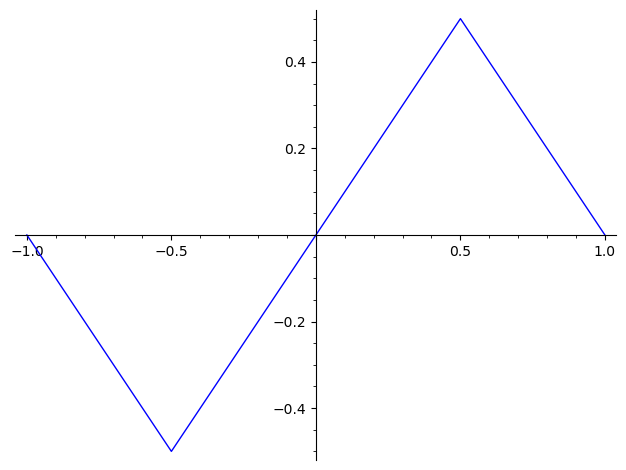

In [37]:
plot(nf, -1, 1)

In [38]:
quad(nf, -1, 1)

(0.0, 5.478623725951253e-15)

In [39]:
quad(nf, 0, 1)

(0.25, 2.7755575615628914e-15)

Observe that ``quad`` returns a tuple.  The first element in the tuple is the approximation for the integral, the second element in the tuple is an estimate for the error.

In defining the basis functions, it is important to use the sine and cosine function of ``numpy`` and also the numerical approximation for $\pi$ of ``numpy``.

## assignment three

Consider the piecewise function $f$ as defined above.

1. Apply numerical integration to compute the coefficients for an approximation $A$ for $f$, for $n=5$.

   Plot the function $f$ and the approximation $A$.

   Also make a plot of the error $\mbox{abs}(f - A)$.

2. Describe the shape of the approximation $A$ and the error.

   Where is the error largest?

### answer to assignment three

In [40]:
import numpy as np

In [41]:
nsf5 = []
nsf5.append(lambda x: np.sin(np.pi*x))
nsf5.append(lambda x: np.sin(2*np.pi*x))
nsf5.append(lambda x: np.sin(3*np.pi*x))
nsf5.append(lambda x: np.sin(4*np.pi*x))
nsf5.append(lambda x: np.sin(5*np.pi*x))

In [42]:
[g(0.32) for g in nsf5]

[0.8443279255020151,
 0.9048270524660195,
 0.1253332335643041,
 -0.7705132427757894,
 -0.9510565162951536]

In [43]:
ncf5 = []
ncf5.append(lambda x: 1.0)
ncf5.append(lambda x: np.cos(np.pi*x))
ncf5.append(lambda x: np.cos(2*np.pi*x))
ncf5.append(lambda x: np.cos(3*np.pi*x))
ncf5.append(lambda x: np.cos(4*np.pi*x))
ncf5.append(lambda x: np.cos(5*np.pi*x))

In [44]:
nF5 = ncf5 + nsf5
nF5

[<function <lambda> at 0x7790a853eef0>,
 <function <lambda> at 0x7790a853ef80>,
 <function <lambda> at 0x7790a853f010>,
 <function <lambda> at 0x7790a853f0a0>,
 <function <lambda> at 0x7790a853f130>,
 <function <lambda> at 0x7790a853f1c0>,
 <function <lambda> at 0x7790a853e4d0>,
 <function <lambda> at 0x7790a853e680>,
 <function <lambda> at 0x7790a853e710>,
 <function <lambda> at 0x7790a853e7a0>,
 <function <lambda> at 0x7790a853e830>]

In [45]:
[fun(0.12) for fun in nF5]

[1.00000000000000,
 0.9297764858882515,
 0.7289686274214116,
 0.42577929156507266,
 0.06279051952931353,
 -0.30901699437494734,
 0.3681245526846779,
 0.6845471059286886,
 0.9048270524660196,
 0.9980267284282716,
 0.9510565162951536]

In [46]:
c = [quad(lambda x: fun(x)*nf(x), -1, 1) for fun in nF5]
c

[(0.0, 5.478623725951253e-15),
 (0.0, 2.5755712520220133e-15),
 (0.0, 3.50496263257488e-15),
 (0.0, 3.5237184076971232e-15),
 (0.0, 3.662145337795345e-15),
 (0.0, 3.3976212704284177e-15),
 (0.4052847345693511, 4.524158825347513e-15),
 (2.3317805771557062e-17, 3.4416913763379853e-15),
 (-0.04503163717437238, 3.7192471324942744e-15),
 (-2.1647499931011903e-17, 3.4416913763379853e-15),
 (0.016211389382773996, 3.58046925441613e-15)]

In [47]:
A = lambda x: c[0][0]/2 + sum([cff[0]*fun(x) for (cff, fun) in zip(c[1:],nF5[1:])])

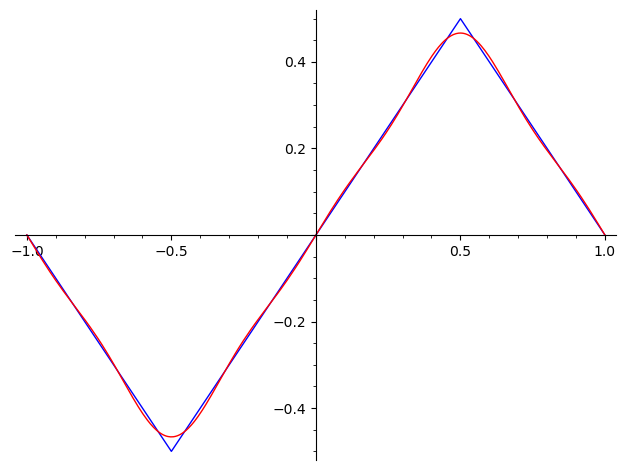

In [48]:
pf = plot(nf, -1, 1)
pA = plot(A, -1, 1, color='red')
show(pf+pA)

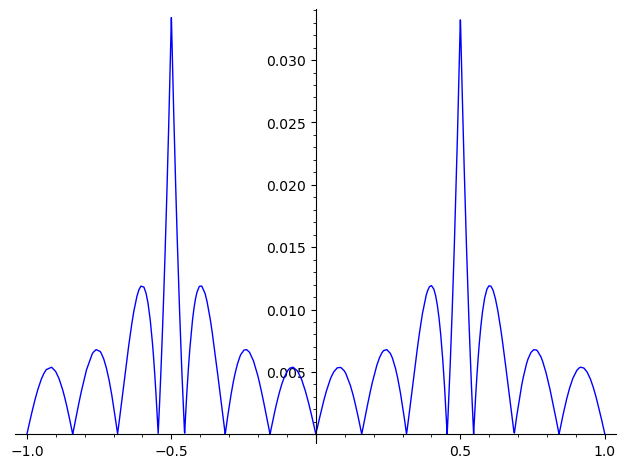

In [49]:
plot(abs(nf(x)-A(x)),x,-1,1)

We observe the following:

1. The shape of the approximation follows the linear shape of the function very well, with roundings at the valley $x=-1/2$ and at the peak $x=1/2$.

2. The error is largest at the discontinuous points, at $x=-1/2$ and $x=1/2$.  

## 5. the Deadline is Wednesday 28 October 2026 at 1pm

Upload your solution to gradescope before 1pm
on Wednesday 28 October 2026.

The solution consists of one single notebook,
organized according to the assignments.
Mark the start of each solution to an assignment using a heading in a cell.
Your notebook should run from top to bottom as a program without errors.
Apply proper formatting in your notebook so it reads
like a technical report if you would print it.
Document the execution cells with complete sentences,
properly formatted in markdown cells.

You may (not must) work in pairs for this project.  
A pair consists of two, not three or more.
If you decide to work in a pair,
then you must send an email with the name of your partner and
with the email address of your partner in the copy of the email
to ``janv@uic.edu``, before 5pm on Wednesday 21 October.
If working in a pair, then only one Jupyter notebook should be submitted.

If you have questions or difficulties with the project,
feel free to ask questions during office hour.